# Smooth run-offs against the run speeds of 2023, and the 2019 sensitivity analysis of the ECB

**Question:** Is the smooth run-off of the ECB's 2019 liquidity stress test, which the product follows, fast enough for the runs of 2023, and how do the survival periods of the product compare with the ones the ECB reported for 103 banks?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 01 to 06 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- place the liquidity stress of the product in the published literature that the research found: the ECB's liquidity stress test of 2019, the Basel principles, the report on the 2023 turmoil and the theory of bank runs;
- compare the smooth run-off of the LiST with the fast run on the same balance sheet, in survival periods and in the share of deposits lost at the horizon of each run of 2023;
- run the third severity of the LiST, Baseline, which the product does not use, and compare the 30-day LCR outflow and the survival periods with the speed of the 2023 runs and with the medians of the ECB;
- say what this comparison does and does not show about the product.
- sweep the size of the CBC against the 2019 medians in one unit and see where the comparison stops discriminating;
- compare variants of your own documents with published runs and medians, with the calendar and the unit stated.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed documents of case C16 (real FDIC call-report aggregates of the bank that failed on 2023-03-10 up to 2022-12-31, synthetic behaviour and deposits, licence class `mirror-allowed`): the three path variants `list-adverse.json`, `list-extreme.json` and `fast-run.json`, and `lcr-standard.json`, all in `data/derived/C16/`. The observed runs are Table A.1 of the BCBS report on the 2023 turmoil, held by the engine as `TABLE_A1` within the BIS limited-extract terms.

The fast run is calibrated on the rows dated before 2023 only and scored on the 2023 rows (notebook 04); every modelled share below is the cumulative outflow of the segments of the document over the deposit base of the model. Amounts are in USD thousands.

In [2]:
# Load the four committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("list-adverse", "list-extreme", "fast-run", "lcr-standard"):
    path = ROOT / "data" / "derived" / "C16" / f"{name}.json"
    documents[name] = json.loads(path.read_text(encoding="utf-8"))
    baked = documents[name]["provenance"]["riskvalidation_version"]
    print(name, "| baked by riskvalidation", baked, "| installed", rv.__version__)

variants = {name: documents[name] for name in ("list-adverse", "list-extreme", "fast-run")}

list-adverse | baked by riskvalidation 1.1.0 | installed 1.1.0
list-extreme | baked by riskvalidation 1.1.0 | installed 1.1.0
fast-run | baked by riskvalidation 1.1.0 | installed 1.1.0
lcr-standard | baked by riskvalidation 1.1.0 | installed 1.1.0


## Method

### Step 1: the survival period of the three variants

The comparison needs one measure that all variants share: the survival period, the first day on which the net liquidity position turns negative, with "survives the horizon" when it never does (notebook 01). The three variants differ in the speed of the run-off: LiST Adverse and Extreme use the smooth daily rates of the ECB's tables, and the fast run puts on the uninsured corporate segment the rate calibrated on the runs before 2023, over an acute horizon of 5 days. The next cell computes the survival period and the minimum NLP of each variant from its committed NLP series with the engine.

In [3]:
# The survival period and the minimum NLP of each variant, from its committed NLP series, with the engine
from riskvalidation.liquidity.ladder import minimum_nlp, survival_period

print(f"{'variant':14s}{'horizon':>9s}{'survival':>24s}{'minimum NLP (USD bn)':>24s}{'day':>6s}")
for name, document in variants.items():
    nlp = np.array(document["outputs"]["path"]["ladder"]["nlp"])
    result = survival_period(nlp)
    low, low_day = minimum_nlp(nlp)
    survival_text = "survives the horizon" if result.survives else f"day {result.day}"
    print(f"{name:14s}{result.horizon:9d}{survival_text:>24s}{low / 1e6:24.2f}{low_day:6d}")

variant         horizon                survival    minimum NLP (USD bn)   day
list-adverse        125                  day 62                  -40.97   125
list-extreme        125                  day 41                  -65.65   125
fast-run              5    survives the horizon                   13.80     1


### Step 2: the share of deposits lost at the horizon of each run

The survival period depends on the CBC and on the outflows together. To compare the speed of the run-off with what happened we use the outflow alone: for a run that lost a share $F_i$ of its deposits in $n_i$ days (row $i$ of Table A.1) the model's counterpart is the cumulative outflow of the segments over the same $n_i$ days, as a share of the deposit base $B$:

$$\hat F_i = \frac{1}{B} \sum_{s} \sum_{d \le n_i} O_s(d), \qquad \text{error}_i = F_i - \hat F_i$$

A row whose horizon exceeds the ladder of a variant cannot be scored on it (the fast run has 5 days). The next cell computes every modelled share from the opening balance and the daily rates of the committed segments with the engine, and prints the rows from the shortest to the longest horizon. A positive error means the model loses less than the run did.

In [4]:
# The modelled share at the horizon of every run of Table A.1, for each variant, from the engine's outflows
from riskvalidation.liquidity.ladder import behavioural_outflows
from riskvalidation.liquidity.runoff import TABLE_A1

modelled = {}
for name, document in variants.items():
    segments = document["outputs"]["path"]["ladder"]["segments"]
    opening = np.array([s["opening_balance"] for s in segments])
    horizon = len(segments[0]["outflows"])
    rates = np.array([s["daily_rates"] or np.ones(horizon) for s in segments])
    base = document["outputs"]["scoring"]["model_deposit_base"]
    outflow = np.cumsum(behavioural_outflows(opening, rates).sum(axis=0))
    shares = {}
    for run in TABLE_A1:
        shares[run.row_id] = None if run.days > len(outflow) else outflow[run.days - 1] / base
    modelled[name] = shares

print(f"{'bank':16s}{'year':>6s}{'days':>6s}{'observed':>10s}{'Adverse':>10s}{'Extreme':>10s}{'fast run':>10s}")
for run in sorted(TABLE_A1, key=lambda r: (r.days, r.year)):
    cells = ["-" if modelled[n][run.row_id] is None else f"{modelled[n][run.row_id]:.4f}" for n in modelled]
    left = f"{run.bank:16s}{run.year:6d}{run.days:6d}{run.outflow_share:10.2f}"
    print(left + f"{cells[0]:>10s}{cells[1]:>10s}{cells[2]:>10s}")

bank              year  days  observed   Adverse   Extreme  fast run
SVB UK            2023     1      0.30    0.0854    0.0887    0.1263
Signature         2023     1      0.20    0.0854    0.0887    0.1263
SVB               2023     2      0.85    0.0915    0.0980    0.1708
Northern Rock     2007     4      0.20    0.1036    0.1164    0.2528
WaMu              2008    10      0.10    0.1390    0.1694         -
IndyMac           2008    14      0.08    0.1618    0.2029         -
Icesave           2008    75      0.20    0.4425    0.5722         -
First Republic    2023    90      0.57    0.4955    0.6323         -
Credit Suisse     2023    90      0.21    0.4955    0.6323         -


The next cell draws the modelled share against the observed share of each run that a variant can score, on logarithmic axes: a point on the diagonal is a model that loses what the run lost, a point under it a model that loses less.

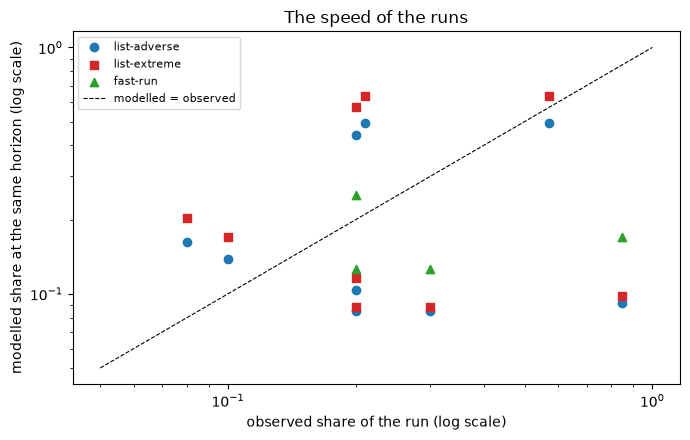

In [5]:
# Draw the modelled against the observed share of each run, for the three variants
fig, ax = plt.subplots(figsize=(7, 4.5))
for (name, shares), color, marker in zip(modelled.items(), ("tab:blue", "tab:red", "tab:green"), ("o", "s", "^")):
    points = [(run.outflow_share, shares[run.row_id]) for run in TABLE_A1 if shares[run.row_id] is not None]
    ax.scatter([p[0] for p in points], [p[1] for p in points], color=color, marker=marker, label=name)
ax.plot([0.05, 1.0], [0.05, 1.0], color="black", linestyle="--", linewidth=0.8, label="modelled = observed")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("observed share of the run (log scale)")
ax.set_ylabel("modelled share at the same horizon (log scale)")
ax.set_title("The speed of the runs")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The points of the fast runs, those of one and two days at the right of the plot, sit under the diagonal, which means that the model loses less than the run did. The three variants lose 0.0854, 0.0887 and 0.1263 of the deposit base on the runs of one day (SVB UK, 0.30, and Signature, 0.20) and 0.0915, 0.0980 and 0.1708 on the two days of SVB (0.85). The fast run, calibrated before 2023, comes closest and still reaches about a fifth of SVB's loss. The slow runs of 2008 and Credit Suisse lie above the diagonal for the smooth variants, that is, those variants cover them, while Northern Rock (0.20 in 4 days, 0.2528 for the fast run) is covered only by the fast run and First Republic (0.57 in 90 days) only by the Extreme variant. The figure compares shares at the horizon of each run and does not say anything about the CBC that stands against them.

## Comparison

What the research found, with the source of each point. Only the sources listed in the SDD are cited.

- **The ECB's liquidity stress test of 2019 (LiST).** It defines the net liquidity position, the survival period and the cliff effect, and runs open-maturity deposits off at constant daily compounding rates on relevant days; in its results 103 banks reported a median survival period of 176 calendar days under the Adverse shock and 122 calendar days under the Extreme shock, and the shocks are idiosyncratic only (ECB, 2019, methodological note and results annex).
- **The Basel principles.** Principle 10 asks banks to stress their liquidity in a variety of short-term and protracted, institution-specific and market-wide scenarios, individually and in combination (BCBS, 2008).
- **The 2023 turmoil.** The BCBS report documents the speed of the runs of 2023 against earlier ones in Table A.1 (SVB 85% in 2 days; First Republic 57% in 90 days) and raises as open questions metrics such as a five-day forward counterbalancing capacity, the survival period and a liquidity metric without run-off assumptions (BCBS, 2023). The Federal Reserve's review found outflows of more than 40 billion USD on 9 March, with management expecting 100 billion more the next day, and that the bank's internal liquidity stress test relied on peer benchmarks that were not comparable (Federal Reserve, 2023).
- **Theory and the digital run.** Diamond and Dybvig (1983) show that a demand-deposit contract has a good equilibrium and a run equilibrium, and that deposit insurance removes the second; the uninsured share is therefore a run-risk driver, not a calibrated model. Cookson et al. (2026) relate exposure to social media to the stock losses of banks in the run on Silicon Valley Bank; the product does not model it.
- **Unrealised losses.** Marking US bank assets to market after the rate rise of 2022 gives large unrealised losses, and these reduce the effective CBC and can trigger runs (Jiang et al., 2024; notebook 03).
- **The model ladder.** The research dossier orders the models of a liquidity stress from a static contractual ladder to a behavioural ladder, a scenario engine, run-speed calibration with sensitivities, and reverse liquidity stress; it found no mature open-source engine for the whole ladder (UNVERIFIED beyond the dossier's search). The product implements the five rungs; funds transfer pricing is not implemented.

The three steps below run the engine on the data of the case against these points: the third severity of the LiST, which the product does not use; the speed of SVB against the tables and the LCR; and the survival periods of the case against the medians that the ECB reported for 103 banks.

### Step 3: the LiST Baseline severity

The 2019 test has three severities, and the product runs two of them as variants. The engine holds the third, Baseline, with the same classes (ECB, 2019, Table 3.3). The next cell composes it on the segments and the ladder of the LiST Adverse document and computes its survival period and its minimum NLP.

In [6]:
# The LiST Baseline severity on the segments and the ladder of the LiST Adverse document
from riskvalidation.liquidity.ladder import net_liquidity_position
from riskvalidation.liquidity.scenarios import compose_scenario, list_scenario

document = variants["list-adverse"]["outputs"]
lad = document["path"]["ladder"]
row = next(r for r in document["conventions"]["variant_scenarios"]["rows"] if r["variant"] == "list-adverse")
segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
args = (row["scenario_family"], row["phase"], list_scenario("baseline"))
scenario = compose_scenario(*args, segments, row["horizon_days"])
contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
total_outflows = scenario.outflows().sum(axis=0) + contractual
baseline_nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
baseline = survival_period(baseline_nlp)
low, low_day = minimum_nlp(baseline_nlp)

print("survives the horizon:", baseline.survives, "| horizon (days):", baseline.horizon)
print("minimum NLP (USD billions) and its day:", round(low / 1e6, 2), low_day)

survives the horizon: True | horizon (days): 125
minimum NLP (USD billions) and its day: 22.06 1


Under Baseline the bank survives the whole horizon, and its NLP never falls below 22.06 billion USD (on day 1, when the financial segment leaves in full): the open-maturity classes of the segments have a zero rate, so the only outflows are that segment and the contractual ones. The severity is not a stress for this balance sheet, which is why the product keeps Adverse and Extreme; it is a floor of the family of tables, with no run in it.

### Step 4: how much faster was 2023 than the tables

Putting the runs and the tables on the same scale takes the implied daily rate of notebook 02 and the ratio of a run to a table:

$$q = 1-(1-F)^{1/n}, \qquad r = \frac{q_{\text{run}}}{q_{\text{table}}}$$

where $F$ is the share lost in $n$ days and $r$ says how many times faster the run leaked than the table. The rate of Silicon Valley Bank (85% in 2 days, counting the outflow management expected for 10 March; Federal Reserve, 2023) against the rate that LiST Adverse and Extreme give to the uninsured corporate class, and against the highest 30-day deposit outflow of the LCR (40% in 30 days, the top of the range in Table A.1), shows the distance. The next cell computes the rates and the ratios.

In [7]:
# The implied daily rate of SVB against the LiST rates of the uninsured corporate class and the top of the LCR range
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, TABLE_A1_LCR_RANGE, daily_rate_from_cumulative

svb = next(run for run in TABLE_A1 if run.row_id == "svb-2023")
corporate = "non-operational-non-financial-corporates"
rates = {severity: LIST_PARAMETERS[severity]["open_maturity"][corporate] for severity in ("adverse", "extreme")}
low_share, high_share, lcr_days = TABLE_A1_LCR_RANGE
rates["lcr top"] = daily_rate_from_cumulative(high_share, lcr_days)
rates["svb"] = daily_rate_from_cumulative(svb.outflow_share, svb.days)

print("implied daily rate of SVB (85 percent in 2 days):", round(rates["svb"], 6))
for name in ("adverse", "extreme", "lcr top"):
    print(f"{name:8s} | daily rate: {rates[name]:.8f} | SVB over it: {rates['svb'] / rates[name]:.1f}")
lcr = documents["lcr-standard"]["outputs"]["lcr"]
print("LCR of the document:", round(lcr["ratio"], 4))
print("net outflow of the LCR over its stock of HQLA:", round(lcr["net_outflows"] / lcr["hqla"]["hqla"], 4))

implied daily rate of SVB (85 percent in 2 days): 0.612702
adverse  | daily rate: 0.00688541 | SVB over it: 89.0
extreme  | daily rate: 0.01065229 | SVB over it: 57.5
lcr top  | daily rate: 0.01688337 | SVB over it: 36.3
LCR of the document: 0.4726
net outflow of the LCR over its stock of HQLA: 2.1158


The next cell draws the four daily rates on a logarithmic axis: the two LiST rates for the uninsured corporate class, the top of the LCR range and the rate of SVB.

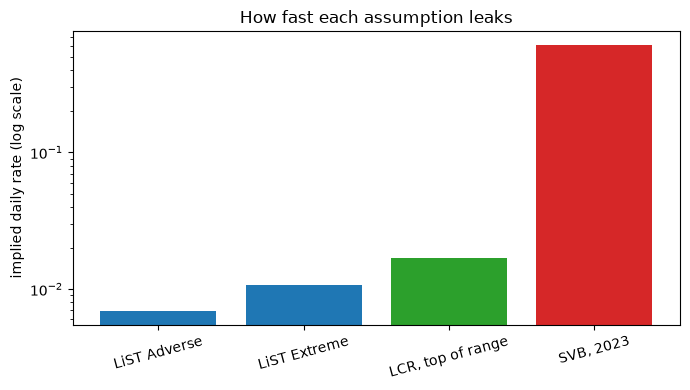

In [8]:
# Draw the daily rates of the LiST tables, the LCR range and SVB on a logarithmic axis
labels = ["LiST Adverse", "LiST Extreme", "LCR, top of range", "SVB, 2023"]
values = [rates["adverse"], rates["extreme"], rates["lcr top"], rates["svb"]]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, values, color=["tab:blue", "tab:blue", "tab:green", "tab:red"])
ax.set_yscale("log")
ax.set_ylabel("implied daily rate (log scale)")
ax.set_title("How fast each assumption leaks")
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
plt.show()

The two LiST rates and the LCR rate lie within a factor of 2.5 of each other, from 0.00688541 to 0.016883 a day, and the rate of SVB is 36 times the highest of them. The LiST rates for the uninsured corporate class, 0.00688541 and 0.01065229 a day, sit at the bottom; the top of the LCR range, 0.016883, is the next step; and the rate of SVB, 0.612702, is 89.0 times the Adverse rate, 57.5 times the Extreme one and 36.3 times the LCR rate. The net outflow of the LCR is 2.1158 times the stock of HQLA, so even the faster of the regulatory assumptions leaves the bank short, but not at the speed of 2023. The bars compare rates implied by one run each: SVB is a single observation.

### Step 5: the survival periods against the medians of the 2019 test

The next cell sets the survival periods of the product beside the medians of the 2019 test. The medians are the ECB's own figures, entered here as constants with their source, because they do not belong to any committed document. They describe 103 real banks, and this case is one synthetic-behaviour bank, so the comparison shows the order of magnitude of the method, not a ranking.

One point of unit decides the comparison. The ECB reports the median survival period in **calendar days**: the axis of its figure reads "Calendar days", and each bank reports the exact date of its survival period among the days that are relevant for the LiST 2019 (ECB, 2019, results annex), which gives 176 and 122. The survival period of the product counts **relevant days** of the calendar of the document, the US business days from 2023-01-03 with the holidays the document lists (a convention of the product, while the ECB's relevant days follow the TARGET2 calendar), and 125 relevant days are 181 calendar days, the six months of the test. The two numbers are not comparable as they stand. The cell converts the survival day of each variant to the calendar days after the valuation date with `numpy.busday_offset` and the calendar of the document, converts the ECB medians to relevant days with `numpy.busday_count` as a second reading, checks that the conversion round-trips on 62, 41 and 125 relevant days, and compares calendar days with calendar days.

In [9]:
# The survival periods of the product beside the medians of the ECB test of 2019, both in calendar days
# median survival period of the 103 banks in calendar days, ECB results annex
LIST_2019_MEDIAN = {"adverse": 176, "extreme": 122}

calendar = variants["list-adverse"]["outputs"]["conventions"]["day_calendar"]
valuation = np.datetime64(variants["list-adverse"]["outputs"]["valuation_date"])
first_day, holidays = np.datetime64(calendar["first_day"]), calendar["holidays"]


def calendar_days_of(relevant_day):
    """Calendar days after the valuation date of a relevant day of the calendar of the document."""
    date = np.busday_offset(first_day, relevant_day - 1, holidays=holidays)
    return int((date - valuation) / np.timedelta64(1, "D"))


def relevant_days_within(calendar_days):
    """Relevant days of the calendar of the document that fall within the given calendar days."""
    end = valuation + np.timedelta64(calendar_days + 1, "D")
    return int(np.busday_count(first_day, end, holidays=holidays))


ours, ours_calendar = {}, {}
headers = ("severity", "relevant day", "calendar days", "median, cal.", "ratio", "median in relevant days")
print(f"{headers[0]:10s}" + "".join(f"{h:>{w}s}" for h, w in zip(headers[1:], (16, 18, 16, 8, 28))))
for severity, name in (("adverse", "list-adverse"), ("extreme", "list-extreme")):
    nlp = np.array(variants[name]["outputs"]["path"]["ladder"]["nlp"])
    ours[severity] = survival_period(nlp).day
    ours_calendar[severity] = calendar_days_of(ours[severity])
    median = LIST_2019_MEDIAN[severity]
    ratio = ours_calendar[severity] / median
    row = f"{severity:10s}{ours[severity]:16d}{ours_calendar[severity]:18d}{median:16d}{ratio:8.2f}"
    print(row + f"{relevant_days_within(median):28d}")
trip = [relevant_days_within(calendar_days_of(day)) for day in (62, 41, 125)]
print("round trip, relevant day to calendar days and back (62, 41 and 125 relevant days):", trip)

severity      relevant day     calendar days    median, cal.   ratio     median in relevant days
adverse                 62                90             176    0.51                         120
extreme                 41                61             122    0.50                          84
round trip, relevant day to calendar days and back (62, 41 and 125 relevant days): [62, 41, 125]


The next cell draws the survival periods of this case against the medians of the 2019 test.

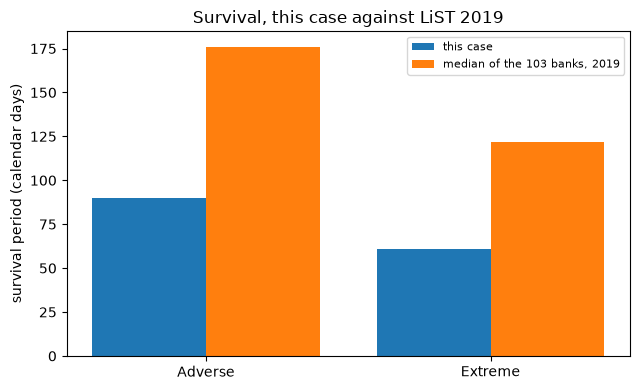

In [10]:
# Draw the survival periods of this case against the medians of the 2019 test, in calendar days
positions = np.arange(2)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(positions - 0.2, [ours_calendar["adverse"], ours_calendar["extreme"]], width=0.4, label="this case")
medians = [LIST_2019_MEDIAN["adverse"], LIST_2019_MEDIAN["extreme"]]
ax.bar(positions + 0.2, medians, width=0.4, label="median of the 103 banks, 2019")
ax.set_xticks(positions)
ax.set_xticklabels(["Adverse", "Extreme"])
ax.set_ylabel("survival period (calendar days)")
ax.set_title("Survival, this case against LiST 2019")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Compared in one unit, the case lasts about half of what the median bank of the 2019 sample reported: 90 calendar days against 176 under Adverse and 61 against 122 under Extreme, ratios of 0.51 and 0.50. Read in relevant days of the calendar of the document the medians are 120 and 84 against 62 and 41. Setting 62 relevant days against 176 calendar days would give 0.35, a ratio that looks like a third and is only a mismatch of units. The two ratios are almost equal, so the shape of the response to severity is the same even though the level differs. The reason is the balance sheet, not the method: the case has a large uninsured corporate base and a CBC that covers only part of it, and the 103 banks are real balance sheets with their own deposits and assets. The conversion is approximate to a few days, because the calendar of the document is a US business-day convention and the ECB's is TARGET2. The figure says that the same method gives survival periods of the order of months; it does not say that the bank ranks below the sample.

### Where the method changes or breaks

The comparison with the ECB sample has one input that a reader can move and that the case does not share with the sample: the size of the counterbalancing capacity. With the CBC scaled by $\kappa$ and the flows kept, the position and the survival period are

$$\mathrm{NLP}_\kappa(t) = \kappa\,\mathrm{CBC}(t) - \sum_{s \le t}\bigl(O(s) - I(s)\bigr), \qquad \mathrm{SP}_\kappa = \min\{\, t : \mathrm{NLP}_\kappa(t) < 0 \,\}$$

and a position that never turns negative inside the ladder is right-censored at the horizon, 125 relevant days or 181 calendar days. The next cell sweeps $\kappa$ from 0.5 to 3 in steps of 0.05 on the Adverse and Extreme ladders with `net_liquidity_position` and `survival_period`, converts each survival day to calendar days with the function of step 5, and finds the smallest multiple at which the case reaches the median of the 103 banks.

In [11]:
# Sweep the size of the CBC: survival in calendar days against the medians of the 2019 test
cbc_multiples = np.round(np.arange(0.5, 3.01, 0.05), 2)
horizon_calendar = calendar_days_of(125)
sweep_days = {}
for severity, name in (("adverse", "list-adverse"), ("extreme", "list-extreme")):
    ladder = variants[name]["outputs"]["path"]["ladder"]
    cbc_base, flows_out = np.array(ladder["cbc_total"]), np.array(ladder["total_outflows"])
    flows_in = np.array(ladder["total_inflows"])
    days = []
    for multiple in cbc_multiples:
        outcome = survival_period(net_liquidity_position(multiple * cbc_base, flows_out, flows_in))
        days.append(None if outcome.survives else calendar_days_of(outcome.day))
    sweep_days[severity] = days

print("horizon of the ladder in calendar days:", horizon_calendar)
print(f"{'CBC multiple':>20s}{'LiST Adverse':>26s}{'LiST Extreme':>26s}")
for multiple in (0.5, 1.0, 1.25, 1.5, 1.6, 1.7, 2.0, 3.0):
    cells = []
    for severity in ("adverse", "extreme"):
        value = sweep_days[severity][int(round((multiple - 0.5) / 0.05))]
        cells.append("survives the horizon" if value is None else str(value))
    print(f"{multiple:20.2f}{cells[0]:>26s}{cells[1]:>26s}")
for severity in ("adverse", "extreme"):
    median = LIST_2019_MEDIAN[severity]
    reached = [m for m, d in zip(cbc_multiples, sweep_days[severity]) if d is None or d >= median]
    print("smallest CBC multiple on the grid that reaches the median:", severity, float(reached[0]))

horizon of the ladder in calendar days: 181
        CBC multiple              LiST Adverse              LiST Extreme
                0.50                        32                        23
                1.00                        90                        61
                1.25                       125                        86
                1.50                       167                       115
                1.60      survives the horizon                       128
                1.70      survives the horizon                       143
                2.00      survives the horizon      survives the horizon
                3.00      survives the horizon      survives the horizon
smallest CBC multiple on the grid that reaches the median: adverse 1.55
smallest CBC multiple on the grid that reaches the median: extreme 1.55


The next cell draws the survival period in calendar days against the size of the CBC for both severities, with the median of the 2019 test of each as a dashed line of the same colour and the horizon of the ladder dotted.

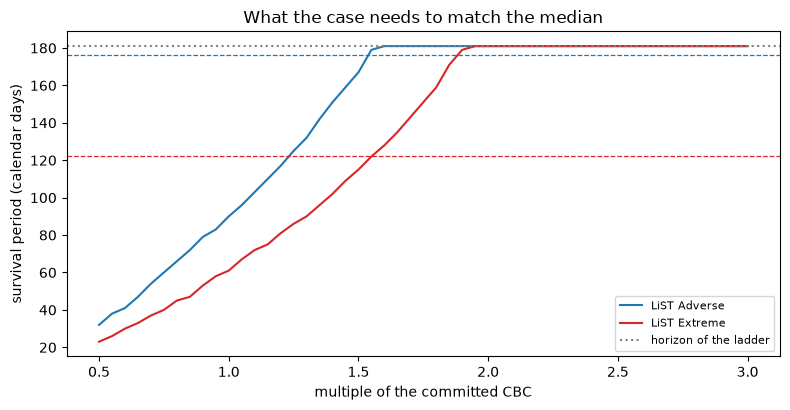

In [12]:
# Draw the survival period in calendar days against the size of the CBC, with the medians and the horizon
fig, ax = plt.subplots(figsize=(8, 4.2))
for severity, color, label in (("adverse", "tab:blue", "LiST Adverse"), ("extreme", "tab:red", "LiST Extreme")):
    shown = [horizon_calendar if d is None else d for d in sweep_days[severity]]
    ax.plot(cbc_multiples, shown, color=color, label=label)
    ax.axhline(LIST_2019_MEDIAN[severity], color=color, linestyle="--", linewidth=0.9)
ax.axhline(horizon_calendar, color="gray", linestyle=":", label="horizon of the ladder")
ax.set_xlabel("multiple of the committed CBC")
ax.set_ylabel("survival period (calendar days)")
ax.set_title("What the case needs to match the median")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Both curves rise almost linearly and reach the censoring line. At the committed size the case lasts 90 calendar days under Adverse and 61 under Extreme; with half the CBC it lasts 32 and 23, and with 1.5 times the CBC 167 and 115. The case reaches the Adverse median (176 days) at 1.55 times its CBC and the Extreme median (122 days) at the same 1.55 times: to match the median bank of the 2019 sample under both severities this balance sheet would need about half as much liquid assets again. That is a more useful reading of the gap than the ratio of 0.5, because it says in what the case differs from the sample.

The comparison fails at the top of the scale. From 1.6 times the Adverse position survives the whole ladder, 181 calendar days, and the Adverse median of 176 days sits within 5 days of that horizon (the annex counts 51 of the 103 banks above six months): the ECB's own median is at the edge of what a six-month test can measure, so for the Adverse severity no larger CBC can be told apart from the median. The Extreme curve is still below the horizon at 1.7 times (143 days) and survives it at 2 times, so it keeps discriminating longer. The sweep scales every component of the CBC together and keeps the outflows, so it does not say which assets the missing capacity would be, and the conversion to calendar days uses the calendar of the document, so the multiple of 1.55 is good to the resolution of the grid and to a few days.

### Using it on your own data

What the comparison needs. A variant document of your own bank with its ladder (`outputs.path.ladder`: the `nlp` series, the `segments` with `opening_balance` and `daily_rates`, `cbc_total` and the flows), its `outputs.scoring.model_deposit_base`, its `outputs.conventions.day_calendar` (`first_day` and the `holidays`) and its valuation date; the observed runs as pairs of outflow share and days (here the 2023 rows of `TABLE_A1`); and the published medians, each with the unit the publisher uses written next to it. The calendar is the part that goes wrong: the engine counts relevant days from 1, and a survival day is a position in your calendar, not a number of calendar days.

The next cell wraps the comparison of this notebook in `variant_report(document, runs)`, which returns the survival period (`survival_period`) and the share that the variant models at the horizon of each run (`behavioural_outflows`, with `None` when the run is longer than the ladder), and runs it on the three committed variants with the five runs of 2023. It prints the date and the calendar days of each survival and then tries four calls that must fail.

In [13]:
# Report the survival, its date and the modelled shares of the runs for the variants of any documents
def variant_report(document, runs):
    """Survival, date and modelled share at the horizon of each run for a variant document."""
    produced = document["outputs"]
    nlp = np.array(produced["path"]["ladder"]["nlp"])
    outcome = survival_period(nlp)
    segments = produced["path"]["ladder"]["segments"]
    opening = np.array([s["opening_balance"] for s in segments])
    horizon = len(segments[0]["outflows"])
    rates = np.array([s["daily_rates"] or np.ones(horizon) for s in segments])
    cumulative_outflow = np.cumsum(behavioural_outflows(opening, rates).sum(axis=0))
    base = produced["scoring"]["model_deposit_base"]
    shares = []
    for share, days in runs:
        daily_rate_from_cumulative(share, days)
        shares.append(None if days > horizon else float(cumulative_outflow[days - 1] / base))
    return outcome, shares


runs_2023 = [run for run in TABLE_A1 if run.year == 2023]
run_ids = [run.row_id for run in runs_2023]
my_runs = [(run.outflow_share, run.days) for run in runs_2023]
for name, document in variants.items():
    outcome, shares = variant_report(document, my_runs)
    if outcome.survives:
        text = "survives the horizon"
    else:
        date = np.busday_offset(first_day, outcome.day - 1, holidays=holidays)
        text = f"{outcome.day}, {date}, {calendar_days_of(outcome.day)}"
    print("variant", name, "|", "survival (relevant day, date, calendar days):", text)
    shown = {run_id: None if s is None else round(s, 4) for run_id, s in zip(run_ids, shares)}
    print("   modelled share at the horizon of each run:", shown)

variant list-adverse | survival (relevant day, date, calendar days): 62, 2023-03-31, 90
   modelled share at the horizon of each run: {'svb-2023': 0.0915, 'first-republic-2023': 0.4955, 'svb-uk-2023': 0.0854, 'credit-suisse-2023': 0.4955, 'signature-2023': 0.0854}
variant list-extreme | survival (relevant day, date, calendar days): 41, 2023-03-02, 61
   modelled share at the horizon of each run: {'svb-2023': 0.098, 'first-republic-2023': 0.6323, 'svb-uk-2023': 0.0887, 'credit-suisse-2023': 0.6323, 'signature-2023': 0.0887}
variant fast-run | survival (relevant day, date, calendar days): survives the horizon
   modelled share at the horizon of each run: {'svb-2023': 0.1708, 'first-republic-2023': None, 'svb-uk-2023': 0.1263, 'credit-suisse-2023': None, 'signature-2023': 0.1263}


The next cell tries the four calls that must fail.

In [14]:
# Four calls that must fail: a share above 1, a run of 0 days, mismatched segments and a missing value
adverse_document = variants["list-adverse"]
trials = {
    "a run with a share above 1": lambda: variant_report(adverse_document, [(1.2, 2)]),
    "a run of 0 days": lambda: variant_report(adverse_document, [(0.5, 0)]),
    "segments and rates that do not match": lambda: behavioural_outflows(np.array([1.0, 2.0]), np.ones((3, 5))),
    "a series with a missing value": lambda: survival_period(np.array([1.0, np.nan])),
}
for label, trial in trials.items():
    try:
        trial()
    except ValueError as error:
        print("refused by the engine:", label, "->", error)

refused by the engine: a run with a share above 1 -> share: must lie in [0, 1], got 1.2
refused by the engine: a run of 0 days -> days: must be at least 1, got 0
refused by the engine: segments and rates that do not match -> opening has 2 segments but daily_rates has 3 rows
refused by the engine: a series with a missing value -> nlp contains non-finite values


What to check in the output. The survival of each variant must reconcile with step 1: day 62 for Adverse, which the calendar puts on 2023-03-31, 90 calendar days after the valuation date, and day 41 for Extreme, on 2023-03-02, 61 days; the fast run survives its 5-day horizon and has no date. The shares are those of step 2 in the order of the 2023 rows (SVB, First Republic, SVB UK, Credit Suisse, Signature): 0.0915 and 0.0854 on the runs of two and one days under Adverse, 0.4955 on the two runs of 90 days, and `None` on the runs that the 5-day fast run cannot reach, so a run longer than the ladder is never extrapolated. Then the refusals: a share above 1, a run of 0 days, segments and rates that do not match in number and a series with a missing value are all rejected with a message that names the problem. Two checks are yours and the engine does not make them: that the calendar of your document is the one under which the published figure was counted, and that a comparison with a published median states its unit, as step 5 did; a survival day set against a median in another unit gives a ratio that looks like a finding and is a mismatch of units.

## Results

**Answer:** No, the smooth run-off is too slow for the runs of 2023. On the runs of one and two days the three variants lose 0.0854 to 0.1263 of the deposit base where SVB UK and Signature lost 0.30 and 0.20, and 0.0915 to 0.1708 where an outflow of 0.85 was reported for SVB. The implied daily rate of SVB, 0.612702, is 89.0 times the rate that LiST Adverse gives to the uninsured corporate class and 36.3 times the top of the LCR deposit range. Against the 2019 test the survival periods of this case, 62 and 41 relevant days, which are 90 and 61 calendar days after the valuation date, are 0.51 and 0.50 of the medians of 103 banks (176 and 122 calendar days), so the method gives months of survival and the balance sheet explains the level.

- **Survival.** The NLP of LiST Adverse turns negative on day 62 and that of Extreme on day 41, both with their minimum on day 125 (-40.97 and -65.65 billion USD); the fast run survives its 5-day horizon, with a minimum of 13.80 billion on day 1. Under the Baseline severity, which the product does not use, the bank survives the horizon and its minimum NLP is 22.06 billion on day 1.
- **Speed at the horizon of each run.** On the runs of one and two days the three variants lose far less than the runs did: 0.0854, 0.0887 and 0.1263 against 0.30 (SVB UK) and 0.20 (Signature), and 0.0915, 0.0980 and 0.1708 against 0.85 (SVB). The fast run, calibrated before 2023, is closer but still about a fifth of SVB's loss. At 90 days the picture changes: Adverse (0.4955) is under First Republic's 0.57 and Extreme (0.6323) is over it, and both are over Credit Suisse's 0.21; the slow runs of 2008 (Icesave, IndyMac, WaMu) are all covered with room to spare, while Northern Rock (0.20 in 4 days against 0.1036 and 0.1164) is not. The smooth rates are conservative for slow runs and far too slow for fast ones.
- **How much faster.** The implied daily rate of SVB, 0.612702, is 89.0 times the rate that LiST Adverse gives to the uninsured corporate class and 57.5 times that of Extreme, and 36.3 times the daily rate at the top of the LCR deposit range (40% in 30 days, 0.016883). The net outflow of the LCR of the document (0.4726) is 2.1158 times its stock of HQLA.
- **Against the published literature.** The survival periods of this case, 62 and 41 relevant days, are 90 and 61 calendar days after the valuation date, about half of the medians of the 2019 test, 176 and 122 calendar days (ratios of 0.51 and 0.50; the medians are 120 and 84 relevant days of the calendar of the document). Setting relevant days against calendar days would give 0.35 and 0.34, a mismatch of units. The 103 banks are real balance sheets with their own deposits and assets, and this case is one bank with synthetic behaviour, so the ratio says that the same method gives survival periods of the order of months, not that the bank ranks below the sample.
- **Where it breaks.** With the CBC scaled from 0.5 to 3 times, the survival is 32 and 23 calendar days at half the CBC, 167 and 115 at 1.5 times, and the case reaches both medians at 1.55 times its CBC. From 1.6 times the Adverse position survives the whole ladder (181 calendar days) and the Adverse median of 176 days sits within 5 days of that horizon, so the comparison cannot tell a larger CBC from the median.
- **Your own data.** The report on the committed variants gives survival day 62 (2023-03-31, 90 calendar days) and 41 (2023-03-02, 61 days), the fast run survives its 5 days, shares of 0.0915 and 0.0854 on the runs of two and one days under Adverse, and `None` where a run is longer than the ladder; the engine refuses a share above 1, a run of 0 days, mismatched segments and a series with a missing value.

What this comparison does not show: that the product's fast run is a forecast (it is a labelled calibration on runs before 2023), that the bank would have survived or failed in these numbers (its behaviour is synthetic), or that the LiST is wrong (it answers the question it was designed for: a slow, idiosyncratic leak over six months).

## Summary

- The smooth LiST run-off and the fast run are two answers to two questions; on the same balance sheet they differ by orders of magnitude in the speed they assume.
- Scored against the runs of 2023, the smooth variants lose far less than the runs of one and two days (SVB UK, Signature, SVB) and are conservative for the slow runs of 2008; the fast run, calibrated only on earlier runs, improves on them and still loses about a fifth of what SVB lost.
- The 30-day LCR outflow is faster than the smooth LiST rates but far slower than the runs of 2023, and the third LiST severity, Baseline, is no stress for this balance sheet.
- The product follows the ECB's method and adds what the dossier lists as the rest of the ladder; it does not claim a forecast.
- Survival periods must be compared in one unit: the ECB reports calendar days and the engine counts relevant days of the calendar of the document, so the case lasts about half of the median bank (0.51 and 0.50) and matches it with about 1.55 times its CBC; the Adverse median is within 5 days of the ladder's horizon and cannot separate larger buffers.

**What to try next.** Change the target of the comparison in step 4 to the run of First Republic (57% in 90 days) and see how far its daily rate is from the LiST tables; then continue with notebook 08, which turns the distance to the 2023 runs into a number.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, results annex (2019-10-07). https://www.bankingsupervision.europa.eu/press/pr/date/2019/html/ssm.pr191007_annex~537c259b6d.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Diamond, D. W. and Dybvig, P. H. (1983), Bank runs, deposit insurance, and liquidity, Journal of Political Economy 91(3). https://doi.org/10.1086/261155
- Cookson, J. A., Fox, C., Gil-Bazo, J., Imbet, J. F. and Schiller, C. (2026), Social media as a bank run catalyst, Journal of Financial Economics 176. https://doi.org/10.1016/j.jfineco.2025.104218
- Jiang, E. X., Matvos, G., Piskorski, T. and Seru, A. (2024), Monetary tightening and U.S. bank fragility in 2023: mark-to-market losses and uninsured depositor runs?, Journal of Financial Economics 159. https://doi.org/10.1016/j.jfineco.2024.103899